# 深度学习基础 - CNN实验
**卢冉 20307130309**

In [26]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torch import nn
import time
from tqdm import tqdm
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

## 3.1 模型代码：

In [29]:
class CNN_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=5)  # 输入通道1（灰度图像），输出通道16，卷积核大小5
        self.pooling1 = nn.MaxPool2d(2, 2)
        self.relu1 = nn.ReLU()

        self.conv2 = nn.Conv2d(16, 32, kernel_size=5)
        self.pooling2 = nn.MaxPool2d(2, 2)
        self.relu2 = nn.ReLU()

        self.fc = nn.Linear(32 * 4 * 4, 10)  # 根据经过前面层后特征图的尺寸计算输入维度，输出维度为10对应10个类别

    def forward(self, x):
        x = self.relu1(self.pooling1(self.conv1(x)))
        x = self.relu2(self.pooling2(self.conv2(x)))
        x = x.view(-1, 32 * 4 * 4)  # 展平特征图
        x = self.fc(x)
        return x


## 3.2 数据准备代码：

In [32]:
batch_size = 64
# 图片转换器
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# 数据集准备 - 训练集与数据加载器
train_dataset = torchvision.datasets.MNIST(root='./data', train=True,
                                            download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size,
                          shuffle=True, num_workers=2)

# 数据集准备 - 测试集与数据加载器
test_dataset = torchvision.datasets.MNIST(root='./data', train=False,
                                           download=True, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=batch_size,
                         shuffle=False, num_workers=2)

## 3.3 训练代码：

In [35]:
def train(epoch, model, criterion, optimizer, train_loader):
    time0 = time.time()  # 记录下当前时间
    loss_list = []
    for e in range(epoch):
        print("start epoch {} training: ".format(e))
        running_loss = 0.0
        model.train()  # 设置模型为训练模式
        for images, labels in tqdm(train_loader):
            optimizer.zero_grad()  # 梯度清零
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()  # 反向传播
            optimizer.step()  # 更新参数
            running_loss += loss.item()
            
        # 一轮循环结束后打印本轮的损失函数
        print("Epoch {} - Training loss: {}".format(e, running_loss / len(train_loader)))
        loss_list.append(running_loss / len(train_loader))
        
    # 打印总的训练时间
    print("\nTraining Time (in minutes) =", (time.time() - time0) / 60)
    return loss_list


## 3.4 测试代码：

In [38]:
def test(model, test_loader):
    model.eval()  # 将模型设置为评估模式
    correct = 0
    total = 0
    all_predicted = []
    all_labels = []
    with torch.no_grad():
        for images, labels in tqdm(test_loader):
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            all_predicted.extend(predicted.tolist())
            all_labels.extend(labels.tolist())
    accuracy = correct / total
    print('Model Accuracy = {:.4f}'.format(accuracy))

    # 绘制混淆矩阵
    cm = confusion_matrix(all_labels, all_predicted)
    print("Confusion Matrix:\n", cm)
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion matrix')
    plt.colorbar()
    tick_marks = range(10)
    plt.xticks(tick_marks, range(10), rotation=45)
    plt.yticks(tick_marks, range(10))
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.show()

    return accuracy, cm


start epoch 0 training: 


100%|█████████████████████████████████████████| 938/938 [00:12<00:00, 72.40it/s]


Epoch 0 - Training loss: 0.5608257563995209
start epoch 1 training: 


100%|█████████████████████████████████████████| 938/938 [00:12<00:00, 76.27it/s]


Epoch 1 - Training loss: 0.1488220193989273
start epoch 2 training: 


...

Epoch 8 - Training loss: 0.05431541467784469
start epoch 9 training: 


100%|█████████████████████████████████████████| 938/938 [00:12<00:00, 73.49it/s]


Epoch 9 - Training loss: 0.05052729229480505

Training Time (in minutes) = 2.1162782510121665


100%|█████████████████████████████████████████| 157/157 [00:02<00:00, 60.15it/s]

Model Accuracy = 0.9860
Confusion Matrix:
 [[ 973    1    0    0    0    1    1    2    2    0]
 [   0 1130    1    0    1    1    0    2    0    0]
 [   2    2 1023    2    0    0    0    1    2    0]
 [   2    0    1  997    0    5    0    3    2    0]
 [   1    0    2    0  964    0    1    2    2   10]
 [   1    0    0    5    0  883    1    1    1    0]
 [   9    4    0    0    1    4  939    0    1    0]
 [   0    3   10    2    0    0    0 1010    2    1]
 [   3    0    2    1    2    3    0    3  958    2]
 [   3    4    0    1    3    5    0    7    3  983]]


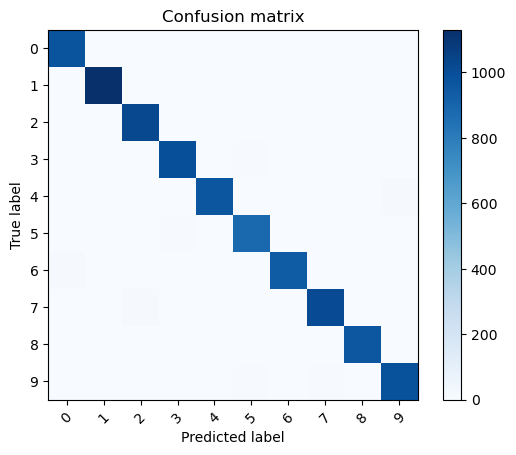

In [40]:
if __name__ == "__main__":
    model = CNN_net()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
    epochs = 10
    train_losses = train(epochs, model, criterion, optimizer, train_loader)
    accuracy, cm = test(model, test_loader)

## 3.5 训练和测试的运行结果截图如上：

## 3.6模型测试的准确率（Accuracy）：
根据测试结果计算：Model Accuracy = 0.9860

## 4.1 该部分可以总结学到的内容、讨论实验过程中遇到的难点。

---
通过完成手写数字MNIST数据集的CNN实验，我对深度学习中的卷积神经网络（CNN）的基本原理、实现方法以及训练过程有了更深入的理解。以下是我的总结和体会：

### 1. 数据准备

#### 代码的含义
- 使用了 `torchvision.datasets` 和 `transforms` 函数，从 MNIST 数据集中加载了训练集和测试集。
- `DataLoader` 提供了批量加载数据的方式，`batch_size` 控制每次训练的样本数量。
- 数据预处理包括：
  - `ToTensor`：将数据转化为张量。
  - `Normalize`：标准化，将数据均值设为 0.5，标准差设为 0.5。

#### 学到的内容
- 数据预处理对训练的影响很大，归一化和标准化有助于更快收敛。
- 批量处理的概念与 SGD（随机梯度下降）算法中的 mini-batch 方法密切相关，能够平衡计算效率和梯度估计的准确性。

#### 遇到的难点
1. 理解 `transforms.Normalize` 的作用初期比较抽象。
   - **解决**：查阅资料了解到这是为了让输入数据分布稳定，从而加速训练。
2. 数据集下载过慢。
   - **解决**：等待服务器响应，随时间的流逝自动解决。

---

### 2. 模型搭建

#### 代码和对应概念的含义
- `CNN_net` 定义了一个简单的 CNN 模型，包括：
  - 两个卷积层 `conv1` 和 `conv2`：用于提取特征。
  - 两个池化层 `pooling1` 和 `pooling2`：用于降维，减小计算量。
  - 激活函数 `relu1` 和 `relu2`：引入非线性能力。
  - 一个全连接层 `fc`：用于将特征映射到分类结果。

#### 原理
- **卷积运算**：通过滑动窗口提取局部特征，数学上可以看作二维矩阵的点积运算。
- **最大池化（MaxPooling）**：通过取窗口最大值减少数据量，增强模型的平移不变性。
- **激活函数 ReLU**：定义为 \( f(x) = \max(0, x) \)，在加速收敛和缓解梯度消失问题上效果显著。

#### 学到的内容
- CNN 的核心在于卷积层的设计，它能捕捉图像局部的空间模式。
- 池化层和激活函数在训练过程中能有效控制模型复杂度，提高模型的表达能力。

#### 遇到的难点
- 初期无法完全理解内部的深层逻辑。
  - **解决**：通过对卷积、池化、激活函数的逐步实验和调试，逐渐掌握其工作原理。

---

### 3. 模型训练

#### 代码和对应变量的含义
- `train` 函数负责训练模型，主要包括：
  - 损失函数 `criterion`：使用交叉熵（`CrossEntropyLoss`），评估模型输出的概率分布与实际标签的匹配程度。
  - 优化器 `optimizer`：使用 Adam 算法，综合了动量和自适应学习率调整的优点。
  - 在每个 `epoch` 中：
    - 前向传播（`model(images)`）：计算预测值。
    - 计算损失（`loss`）：衡量预测值和真实值的差异。
    - 反向传播（`loss.backward()`）：计算梯度。
    - 更新权重（`optimizer.step()`）：通过优化器调整参数。

#### 学到的内容
- 损失函数的数学本质是目标分布与预测分布的交叉熵，表示分类任务中模型的不确定性。
- 反向传播通过链式法则计算梯度，优化器则基于梯度调整参数。
- 模型的训练过程本质是一个优化问题，通过最小化损失函数，使模型的预测尽可能接近真实值。

#### 遇到的难点
1. 损失值下降速度慢。
   - **解决**：查阅资料后了解可以通过降低学习率或增加 `epoch` 解决。

---

### 4. 模型测试

#### 代码的含义
- `test` 函数负责评估模型性能，主要包括：
  - **准确率**：计算模型在测试集上的预测准确率，作为性能的直接衡量指标。
  - **混淆矩阵**：显示分类错误的模式，分析模型的优劣。

#### 学到的内容
- 模型评估需要与训练过程隔离，防止模型对测试数据泄漏。
- 混淆矩阵是一种可视化工具，有助于分析哪些类别容易混淆，以及模型可能的改进方向。

#### 遇到的难点
- 理解混淆矩阵的具体含义。
  - **解决**：通过绘制和分析混淆矩阵，逐步理解各项指标的实际意义。

---

### 总结
通过本次实验，我系统掌握了卷积神经网络的核心原理与实现方法，并获得了数据处理、模型搭建、训练优化和性能评估等全方位的实践经验。尽管在过程中遇到了一些困难，但通过查阅资料、调试代码和反复实践，我对深度学习的理论和实际应用有了更深的认识。
